<a href="https://colab.research.google.com/github/yalini154/1/blob/main/image_classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Input, Dense, Flatten, Dropout, Conv2D, MaxPooling2D
from tensorflow.keras.constraints import max_norm
from tensorflow.keras.utils import to_categorical, load_img, img_to_array
from tensorflow.keras.optimizers import SGD
from numpy import argmax
import numpy as np
import os
from PIL import Image

In [2]:
!wget -q https://s3.amazonaws.com/fast-ai-imageclas/cifar10.tgz

!tar -xzf cifar10.tgz

['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


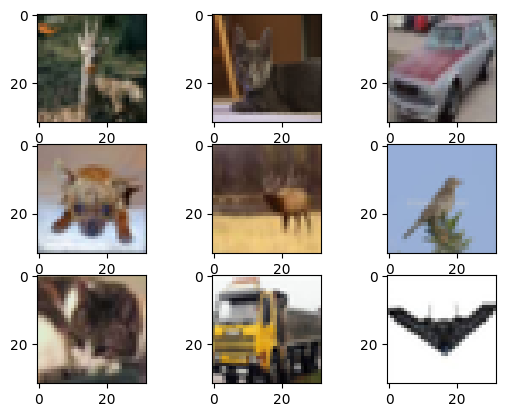

In [5]:
import matplotlib.pyplot as plt

def load_split(folder):
  class_names = sorted(os.listdir(folder))
  images, labels = [], []
  for label, class_name in enumerate(class_names):
    class_dir = os.path.join(folder, class_name)
    for filename in os.listdir(class_dir):
      img = Image.open(os.path.join(class_dir, filename)).convert('RGB')
      images.append(np.array(img))
      labels.append(label)
  x = np.array(images)
  y = np.array(labels).reshape(-1, 1)

  shuffle_order = np.random.permutation(len(x))
  return x[shuffle_order], y[shuffle_order], class_names

x_train, y_train, train_class_names = load_split('cifar10/train')
x_test, y_test, _ = load_split('cifar10/test')

print(train_class_names)

for i in range(9):
  plt.subplot(330 + 1 + i)
  plt.imshow(x_train[i])
plt.show()

In [7]:
num_classes = len(train_class_names)

train_size = 8000
test_size = 2000
x_train = x_train[:train_size]
y_train = y_train[:train_size]
x_test = x_test[:test_size]
y_test = y_test[:test_size]

y_train = to_categorical(y_train, num_classes)
y_test = to_categorical(y_test, num_classes)

x_train = x_train.astype('float32') / 255
x_test = x_test.astype('float32') / 255

print('x_train shape: ', x_train.shape)
print(x_train.shape[0], 'train samples')
print(x_test.shape[0], 'test samples')

x_train shape:  (8000, 32, 32, 3)
8000 train samples
2000 test samples


In [ ]:
model = Sequential()
model = add(Input(shape=(32, 32, 3)))
model = add(Conv2D(16, (3, 3)m activation='relu', padding='same'))
model = add(Dropout(0.2))
model = add(MaxPooling2D(pool_size=(2, 2)))
model = add
model = add(Flatten())
model = add(Dropout(0.2))
model = add(Dense(128, activantion='relu', kernel_constraint=max_norm(3)))
model = add(Dropout(0.2))
model = add
model = add
model = add

In [10]:
model = Sequential()

model.add(Input(shape=(32, 32, 3)))

model.add(Conv2D(16, (3, 3), activation='relu', padding='same'))

model.add(Dropout(0.2))

model.add(MaxPooling2D(pool_size=(2, 2)))

model.add(Conv2D(32, (3, 3), activation='relu', padding='same'))

model.add(Dropout(0.2))

model.add(MaxPooling2D(pool_size=(2, 2)))

model.add(Flatten())

model.add(Dropout(0.2))

model.add(Dense(128, activation='relu', kernel_constraint=max_norm(3)))

model.add(Dropout(0.2))

model.add(Dense(num_classes, activation='softmax'))

opt = SGD(learning_rate=0.01, momentum=0.9, nesterov=False)

model.compile(loss='categorical_crossentropy', optimizer=opt, metrics=['accuracy'])

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32, 32, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 268,650 (1.02 MB)

 Trainable params: 268,650 (1.02 MB)

 Non-trainable params: 0 (0.00 B)

In [12]:
model.fit(x_train, y_train, batch_size=32, epochs=10, verbose=1, validation_data=(x_test, y_test))
print('The model has successfully trained')

model.save('classifier.keras')
print('Saving the model as classifier.keras')

Epoch 1/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 8s 26ms/step - accuracy: 0.2256 - loss: 2.0922 - val_accuracy: 0.3695 - val_loss: 1.8595
Epoch 2/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 10s 26ms/step - accuracy: 0.3605 - loss: 1.7700 - val_accuracy: 0.4305 - val_loss: 1.6431
Epoch 3/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 11s 42ms/step - accuracy: 0.4243 - loss: 1.6074 - val_accuracy: 0.4365 - val_loss: 1.5785
Epoch 4/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 18s 32ms/step - accuracy: 0.4521 - loss: 1.5218 - val_accuracy: 0.4955 - val_loss: 1.4795
Epoch 5/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 11s 36ms/step - accuracy: 0.4850 - loss: 1.4282 - val_accuracy: 0.4700 - val_loss: 1.4491
Epoch 6/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 8s 28ms/step - accuracy: 0.5170 - loss: 1.3399 - val_accuracy: 0.4760 - val_loss: 1.4633
Epoch 7/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 8s 31ms/step - accuracy: 0.5412 - loss: 1.2766 - val_accuracy: 0.4960 - val_loss: 1.4318
Epoch 8/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 10s 30ms/step - accuracy: 0.5636 - loss: 1.2260 - val

In [13]:
score = model.evaluate(x_test, y_test, verbose=0)
print('Test loss:', score[0])
print('test accuracy', score[1])

Test loss: 1.371451497077942
test accuracy 0.5095000267028809
